In [1]:
from unbiased_mcmc import *

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html


In [2]:
import numpy as np 
def log_target0(x):
    return -0.5 * np.sum(x**2, axis=-1)

def log_target1(x, D):
    return -0.5 * np.sum((x - D)**2, axis=-1)


def g_log_target(x, path, D):
    return (1 - path) * log_target0(x) + path * log_target1(x, D)


def g_grad_log_target(x, D):
    return log_target1(x, D) - log_target0(x)

In [3]:
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L # uniform grid of lambda values in [0, 1]

In [4]:

d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)


alpha = 3 #  scale 
D = alpha * np.array([1.0] * d)  # mean shift of the target distribution

log_target_path = lambda x, path: g_log_target(x, path, D)
grad_log_target_path = lambda x, path: g_grad_log_target(x, D)

In [6]:
mk_grid = tune_km_grid(
    lambda_grid,
    mean_init,
    Sigma_init,
    Sigma,
    cholesky_Sigma,
    inv_cholesky_Sigma,
    log_target_path,
    lag=1,
    nrep=1000,
)

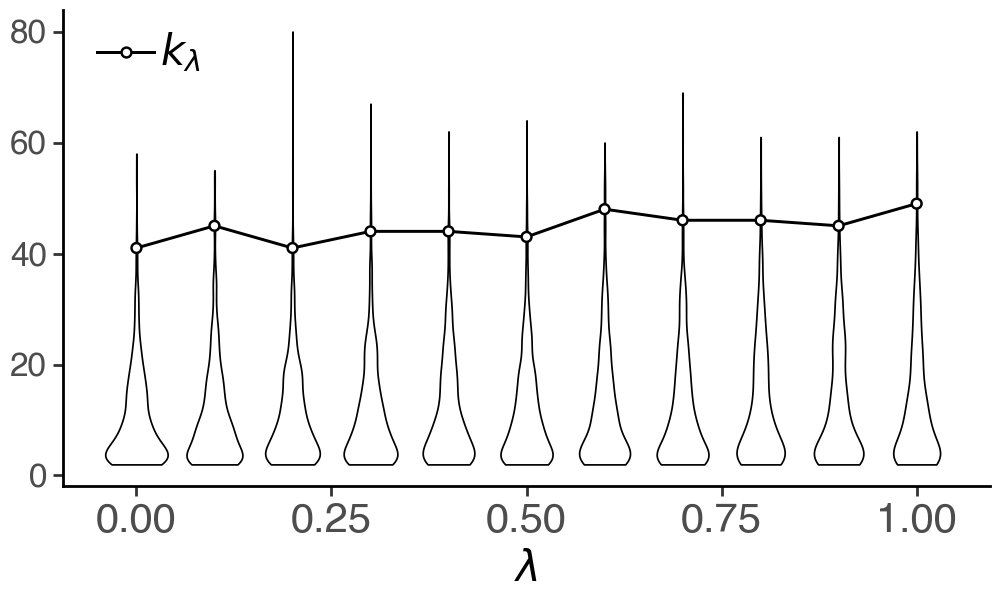

In [7]:
plot_km_grid(mk_grid, lambda_grid)

In [8]:
k_grid = mk_grid["k_grid"]
m_grid = mk_grid["m_grid"]
lag = k_grid

In [9]:
moment_results = estimate_moments(
        lambda_grid,
        k_grid,
        m_grid,
        mean_init,
        Sigma_init,
        Sigma,
        cholesky_Sigma,
        inv_cholesky_Sigma,
        log_target_path,
        grad_log_target_path,
        lag=1,
        nrep=1000,
    )

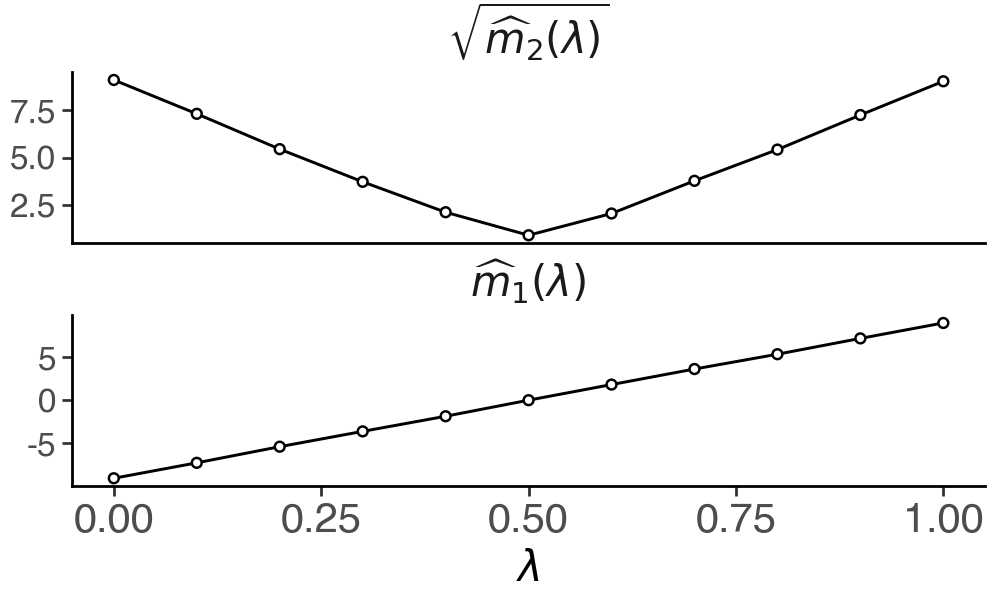

In [10]:
plot_m1_m2(moment_results, lambda_grid)

In [11]:
m2 = moment_results["m2"] # to define the optimal proposal for UPS

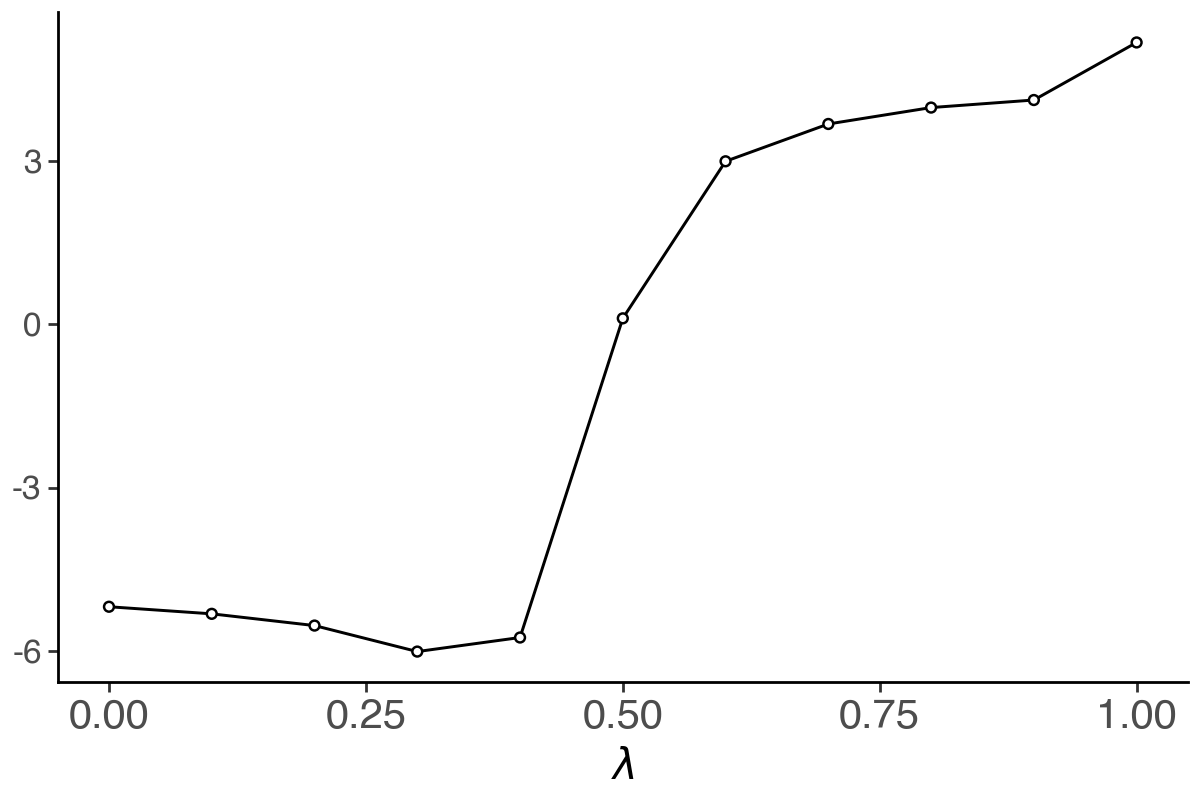

In [11]:
plot_E_lambda_over_q(
	lambda_grid,
	m2,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	nrep=1000,
)

In [12]:
N_pilot = 1000
sigma = estimate_sigma(lambda_grid, k_grid, m_grid, lag, mean_init, Sigma_init, Sigma, cholesky_Sigma, inv_cholesky_Sigma, log_target_path, grad_log_target_path, N_pilot)

IS replications: 100%|██████████| 100/100 [00:00<00:00, 1929.09it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


Workers=14 | M_IS=25727 | coût moyen UPS=25727.7 | coût moyen SUPS=25727.0
MSE: {'UPS': np.float64(0.27997046601075726), 'SUPS': np.float64(0.011101241843337521), 'IS': np.float64(0.6753860378827788)}


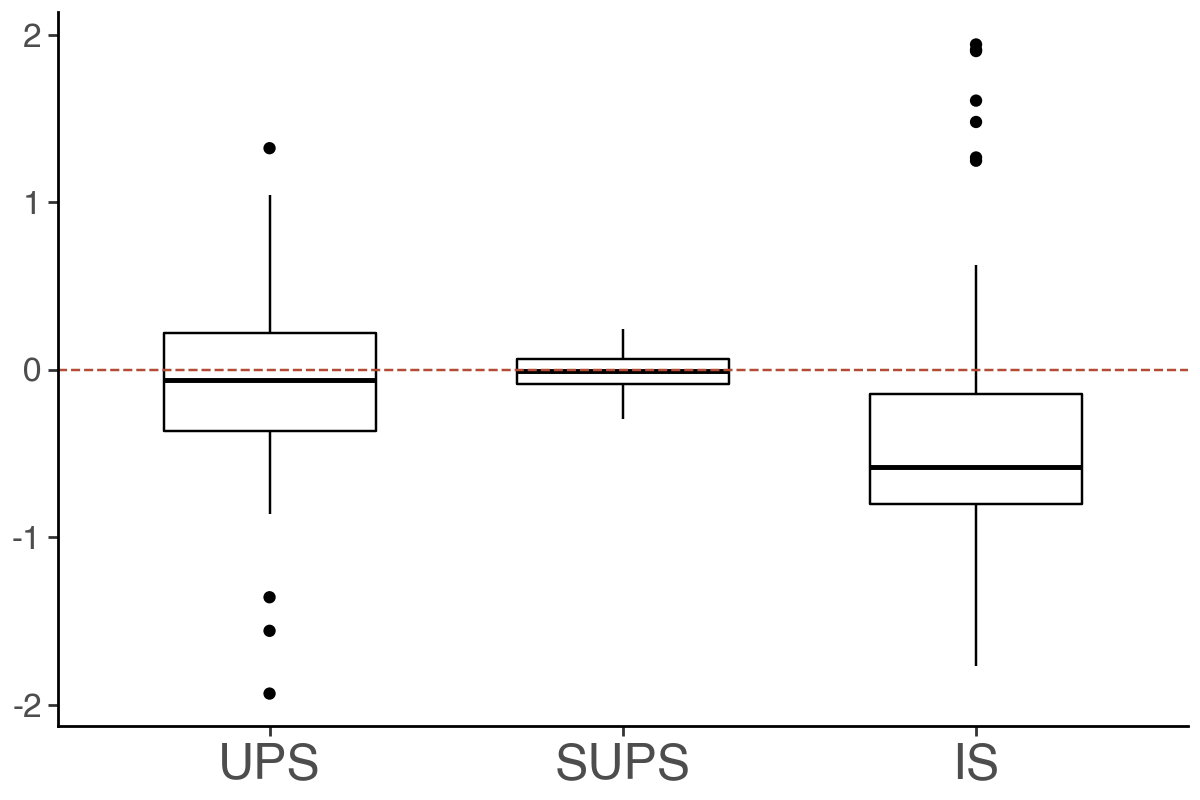

{'UPS_values': array([ 2.12291222e-01, -3.23067980e-02,  1.15941606e-02,  4.15727524e-01,
         6.89592159e-01, -2.73932821e-01, -4.32561042e-01, -1.76112356e-01,
         1.17243297e-01, -2.92594036e-01, -2.76510832e-01,  4.27013828e-02,
         2.65011142e-01,  7.62758747e-02,  1.44900251e-01, -1.78494405e-01,
        -3.82117198e-01, -1.55688981e+00, -1.35611013e-01, -4.76333192e-01,
        -7.19003760e-01, -1.35797966e-01, -1.68233051e-01, -1.26421145e-01,
         7.11065822e-02, -1.35663569e+00, -7.55528323e-01,  1.47767889e-03,
        -8.32697014e-01, -4.32449341e-01, -7.76203284e-01, -1.42161854e-01,
        -6.59730371e-01, -5.18530032e-01, -4.55565001e-01,  4.83591663e-01,
        -8.62229804e-01,  5.85627492e-01,  8.70306073e-02,  3.59037083e-01,
        -1.93124667e+00,  5.24128643e-01,  3.60880886e-01,  2.03551252e-01,
        -3.14295885e-01,  2.36654753e-01,  2.02673510e-01, -5.84843687e-01,
        -2.05091875e-01, -1.64355602e-01, -6.59530184e-01,  9.37872852e-01

In [26]:
compare_estimators(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
    D,
	d,
	M=100,
	nrep=100,
	true_value=0.0,
	n_workers=14,
)

IS prefixes (max M=261968): 100%|██████████| 50/50 [00:00<00:00, 188.15it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


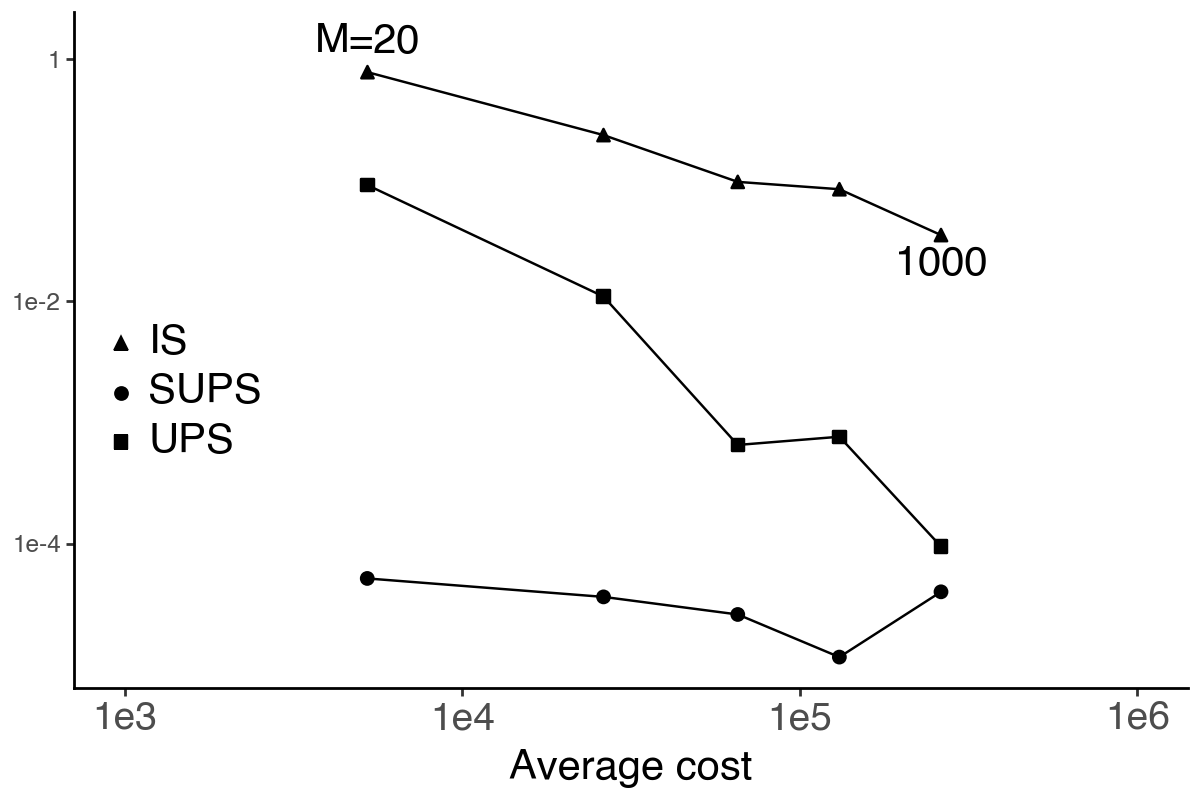

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


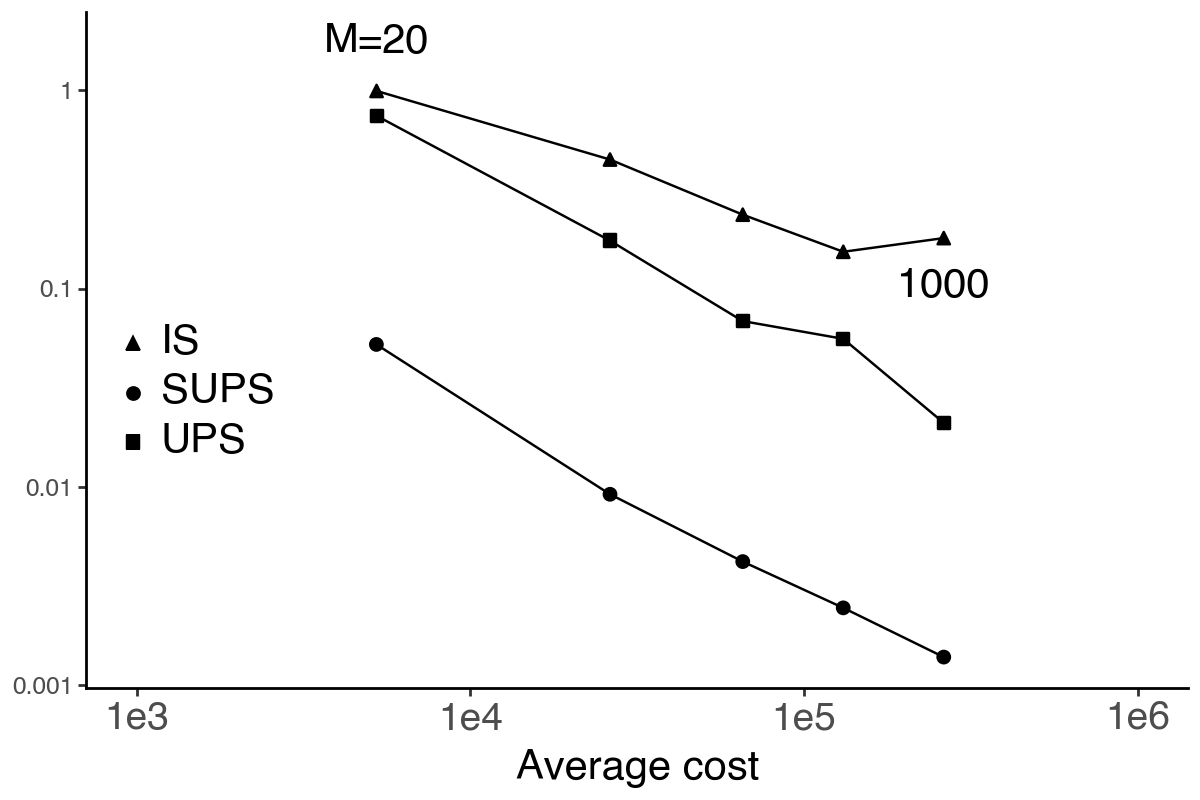

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


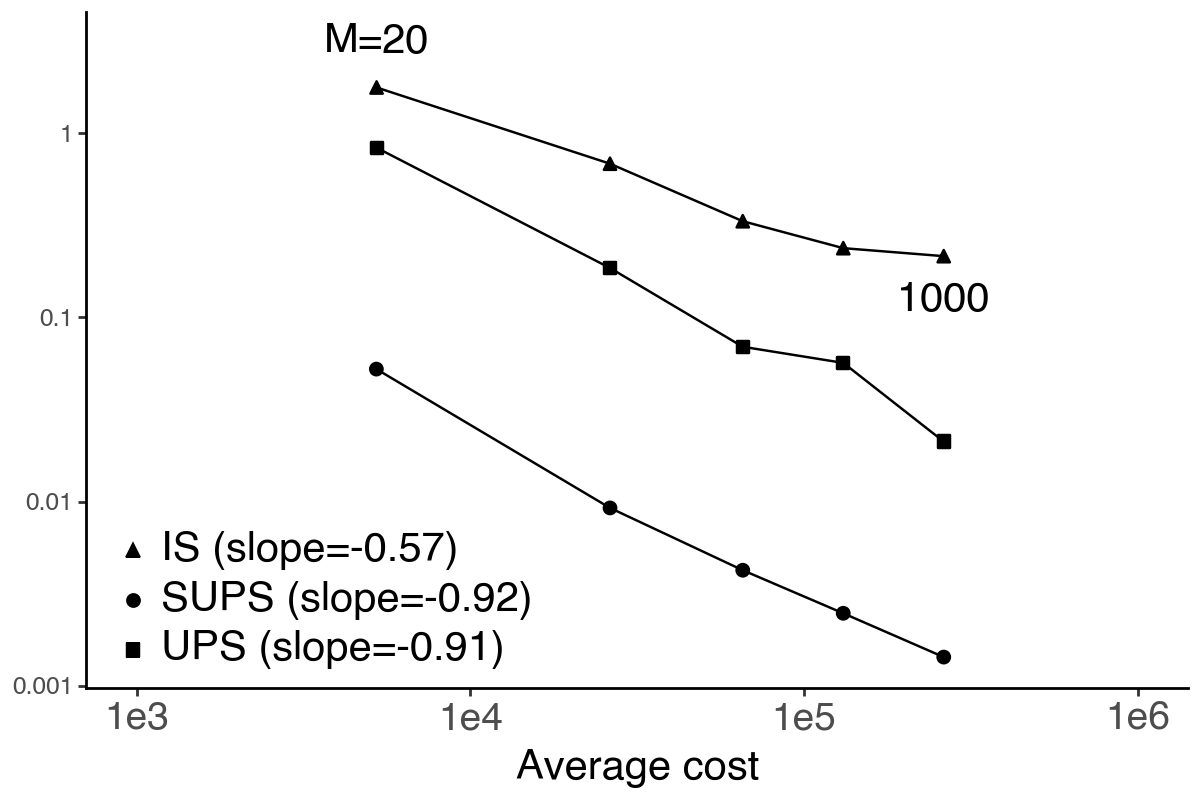

{'data':        M Estimator       Cost  Bias squared  Variance       MSE    M_is
 0     20       UPS    5244.92      0.090816  0.741743  0.832559    5238
 1     20      SUPS    5230.84      0.000051  0.052302  0.052353    5238
 2     20        IS    5238.00      0.779620  0.990775  1.770395    5238
 3    100       UPS   26199.88      0.010952  0.174404  0.185356   26207
 4    100      SUPS   26213.14      0.000036  0.009191  0.009227   26207
 5    100        IS   26207.00      0.235700  0.446970  0.682670   26207
 6    250       UPS   65482.06      0.000652  0.068565  0.069216   65485
 7    250      SUPS   65488.28      0.000026  0.004209  0.004235   65485
 8    250        IS   65485.00      0.096819  0.235739  0.332558   65485
 9    500       UPS  131034.86      0.000762  0.055809  0.056570  131003
 10   500      SUPS  130971.50      0.000012  0.002460  0.002472  131003
 11   500        IS  131003.00      0.084202  0.153265  0.237467  131003
 12  1000       UPS  261952.36      0.00009

In [13]:
import importlib

normal_plots = importlib.import_module("unbiased_mcmc.normal_plots")
normal_plots = importlib.reload(normal_plots)
compare_estimators_mse_by_budget = normal_plots.compare_estimators_mse_by_budget

compare_estimators_mse_by_budget(
	lambda_grid,
	m2,
	sigma,
	k_grid,
	m_grid,
	lag,
	mean_init,
	Sigma_init,
	Sigma,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target_path,
	grad_log_target_path,
	log_target0,
	log_target1,
	D,
	d,
	M_values=(20, 100, 250, 500, 1000),
	nrep=50,
	true_value=0.0,
	n_workers=14,
)

#tuple(np.geomspace(20, 1000, 5).round().astype(int))

In [3]:
d = 2
Sigma = np.eye(d) # covaraince of the proposal of RWMH
mean_init = np.array([-2.0] * d) # mean for the initial distribution of MH
Sigma_init = np.eye(d) # covariance of the initial ditribution of MH
cholesky_Sigma = cholesky(Sigma)
inv_cholesky_Sigma = inv_cholesky(Sigma)
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L 


In [ ]:
plot_mse_by_alpha(
	lambda_grid,
	Sigma,
	mean_init,
	Sigma_init,
	cholesky_Sigma,
	inv_cholesky_Sigma,
	log_target0,
	log_target1,
	alpha_values=(0.5, 1, 2, 3, 4),
    
	M=50,
	nrep=5,
	n_tune=100,
	n_moments=100,
	n_pilot=100,
	n_workers=14)

KeyboardInterrupt: 

In [2]:
L = 10  # 0, 0.1, ..., 1.0
lambda_grid = np.arange(0, L + 1) / L 

IS prefixes (max M=1013205): 100%|██████████| 5/5 [00:00<00:00,  7.94it/s]
/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


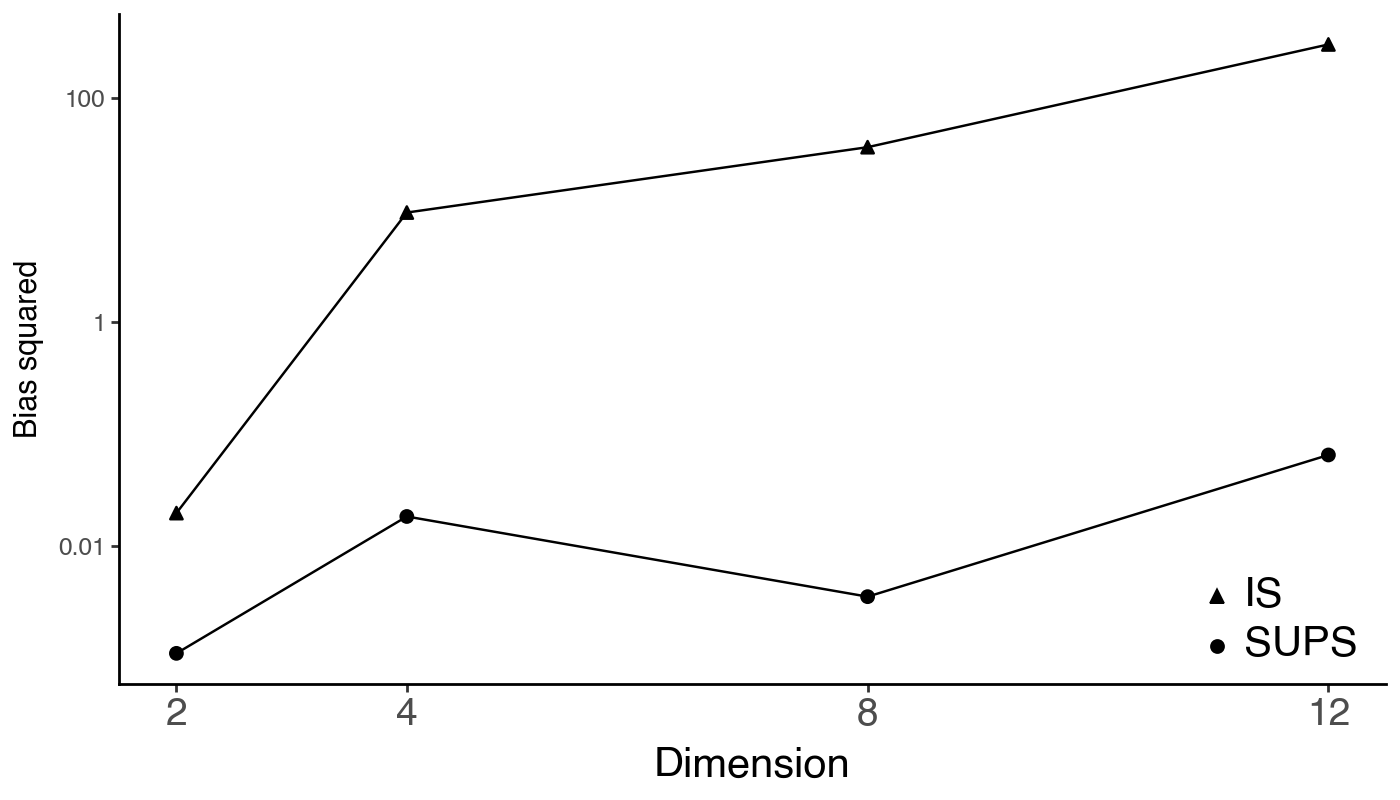

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


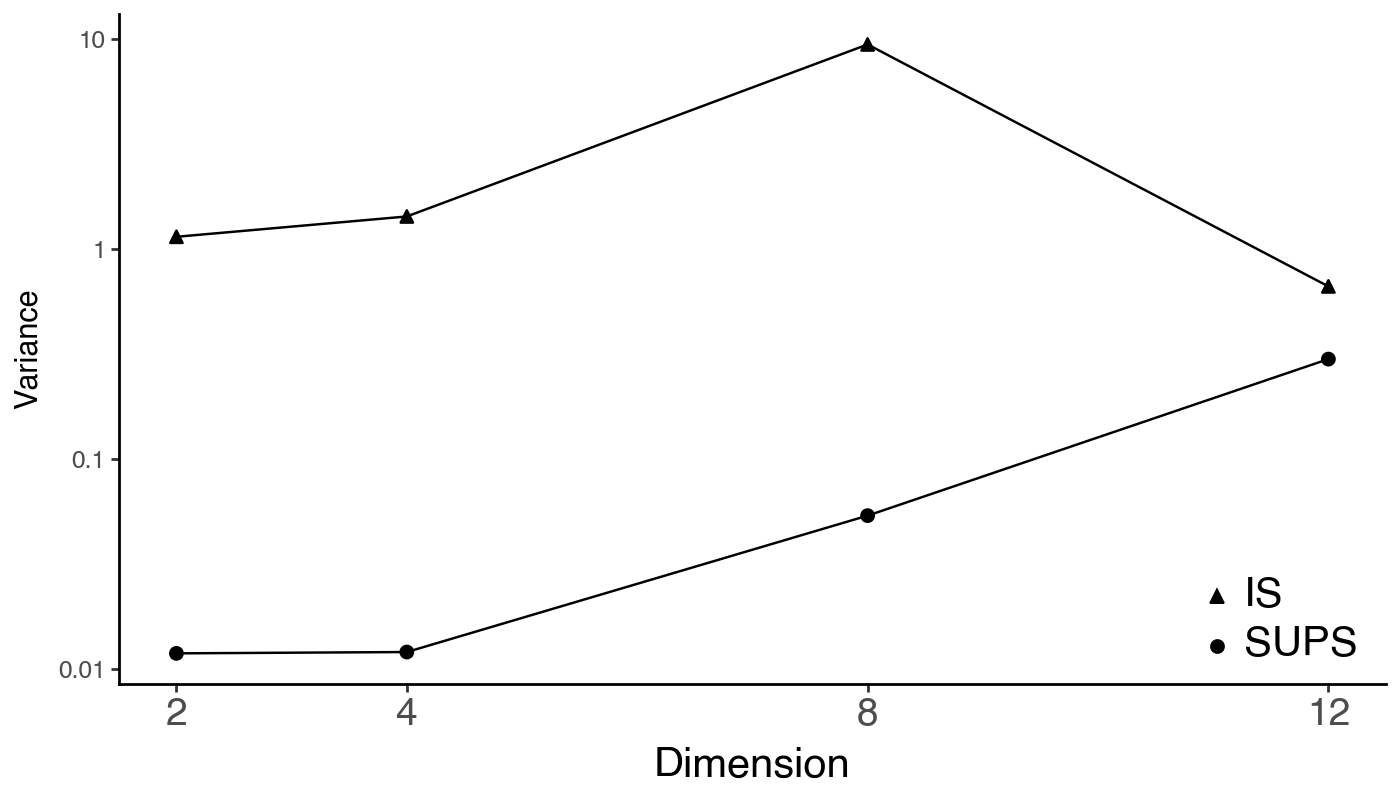

/Users/b00829592/pathsampling-env/lib/python3.9/site-packages/IPython/lib/pretty.py:778: FutureWarning: Using repr(plot) to draw and show the plot figure is deprecated and will be removed in a future version. Use plot.show().


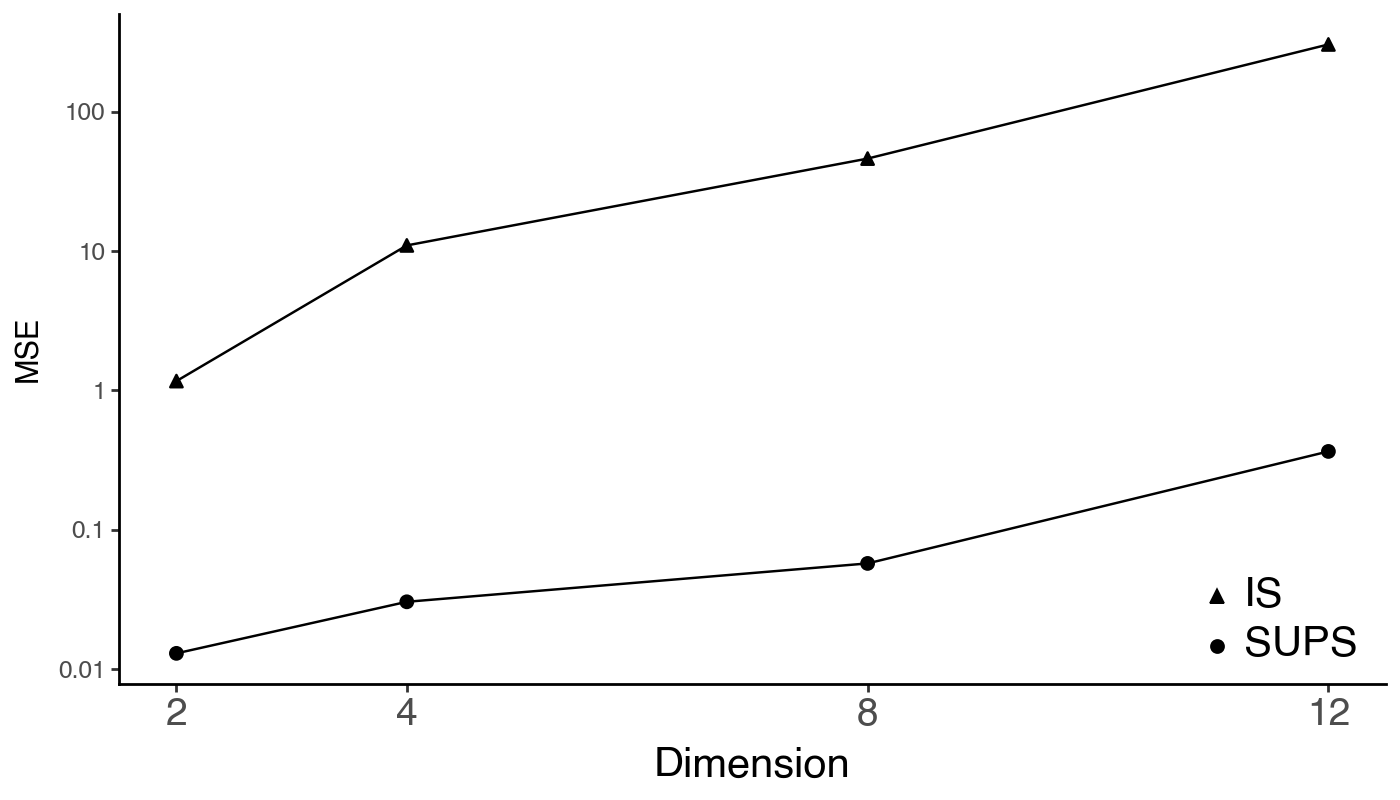

{'data':      M Estimator       Cost  Bias squared  Variance         MSE     M_is  \
 0   50      SUPS    14057.0      0.001103  0.011910    0.013013    14060   
 1   50        IS    14060.0      0.019741  1.148405    1.168146    14060   
 2  100      SUPS    49473.6      0.018412  0.012085    0.030496    49429   
 3  100        IS    49429.0      9.546279  1.435091   10.981370    49429   
 4  200      SUPS   351966.8      0.003540  0.053940    0.057480   352011   
 5  200        IS   352011.0     36.619509  9.467105   46.086614   352011   
 6  300      SUPS  1013362.0      0.065243  0.300239    0.365482  1013205   
 7  300        IS  1013205.0    302.921083  0.666396  303.587479  1013205   
 
    Dimension  
 0          2  
 1          2  
 2          4  
 3          4  
 4          8  
 5          8  
 6         12  
 7         12  ,
 'plots': {'Bias squared': <Figure Size: (700 x 400)>,
  'Variance': <Figure Size: (700 x 400)>,
  'MSE': <Figure Size: (700 x 400)>},
 'by_dimension': 

In [4]:
compare_estimators_mse_by_dimension(
	lambda_grid,
	log_target0,
	log_target1,
	dimensions=(2, 4, 8, 12),
	M_by_dimension= {2: 50, 4: 100, 8: 200, 12: 300},
	alpha=3.0,
	nrep=5,
	lag=1,
	init_mean=-2.0,
	init_variance=1.0,
	n_tune=100,
	n_pilot=100,
	n_moments=100,
	n_workers=14,
)